# Demand Forecasting & Commercial Gap Analysis
Japan Contact Lens Portfolio | Historical: Oct 2024 – Sep 2026 (24M) | Forecast: Oct 2026 – Mar 2027 (6M)

## Overview

This project models commercial planning for a synthetic Japan contact lens dataset across 4 brands and 4 sales channels. Monthly shipments come from two streams:
- **Recurring demand**: regular patient and account refills for daily and bi-weekly lenses (`demand_stream == 'Recurring'`; in production ERP data this is tagged via patient subscription IDs and account reorder cadence).
- **Non-recurring demand**: hospital tenders, new retail chain rollouts, and seasonal bulk deals.

Forecasting total shipments with a single model treats one-off promotional spikes as permanent growth. Separating the two streams lets us forecast the recurring refill baseline first, compare the remaining non-recurring quota against the historical non-recurring run-rate, and convert physical pieces into net revenue (JPY) using channel contra rates.

### Key Results (Oct 2026 – Mar 2027)
- **Recurring volume**: projected at 730.3M pcs against a 1,014.2M pcs budget (72.0% coverage), with a 5,000-run multi-step bootstrap range of 721.6M (P10) to 739.9M pcs (P90).
- **Non-recurring quota vs. historical run-rate**: subtracting recurring volume from budget leaves 283.9M pcs of non-recurring demand. Over the last 6 months, non-recurring orders averaged 249.7M pcs (25.7% of shipments), so **+34.2M pcs** is true incremental commercial stretch above the usual run-rate.
- **Supply capacity**: total factory and inventory planning must cover the full 1,014.2M pcs target plus the +9.6M pcs recurring P90 buffer (1,023.8M pcs total).
- **Net revenue gap**: after channel rebates, recurring demand delivers ¥19,360.4M (P10 floor: ¥19,144.3M) against the ¥27,233.7M net sales target. Of the ¥7,873.3M non-recurring quota, ¥6,899.5M is historical run-rate and **+¥973.8M** is net incremental stretch, led by Brand B (+¥624.5M).

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

sys.path.insert(0, os.path.abspath(".."))
import src

AZURE = {
    "navy": "#03197C",
    "royal": "#094194",
    "medium": "#1179B6",
    "cyan": "#1BC2E2",
    "aqua": "#20E4F6",
}

AMBER = {
    "deep": "#F8870A",
    "orange": "#F99D19",
    "gold": "#FBBC2F",
    "yellow": "#FDE44B",
    "lemon": "#FFF758",
}

plt.rcParams["axes.prop_cycle"] = plt.cycler(
    color=[AZURE["navy"], AMBER["deep"], AZURE["medium"], AMBER["gold"], AZURE["cyan"], AMBER["orange"]]
)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Segoe UI", "Arial"]
plt.rcParams["font.size"] = 10
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["grid.color"] = "#E2E8F0"
plt.rcParams["figure.autolayout"] = True

data_dir = os.path.join("..", "data")
fig_dir = os.path.join("..", "figures")
os.makedirs(fig_dir, exist_ok=True)

dim_cal = pd.read_csv(os.path.join(data_dir, "dim_calendar.csv"))
dim_chan = pd.read_csv(os.path.join(data_dir, "dim_channel.csv"))
dim_prod = pd.read_csv(os.path.join(data_dir, "dim_product.csv"))
fact_rec = pd.read_csv(os.path.join(data_dir, "fact_recurring_split.csv"))
fact_sales = pd.read_csv(os.path.join(data_dir, "fact_sales_transaction.csv"))
fact_target = pd.read_csv(os.path.join(data_dir, "fact_target_budget.csv"))
fact_contra = pd.read_csv(os.path.join(data_dir, "fact_trade_contra.csv"))

fut_start = dim_cal.loc[dim_cal["is_future_target_horizon"] == 1, "period_date"].min()
fut_tgt_slice = fact_target[fact_target["period_date"] >= fut_start]
print("Data Loaded:")
print(f"  - Calendar Horizon    : {len(dim_cal)} months ({dim_cal['period_date'].min()} to {dim_cal['period_date'].max()})")
print(f"  - Brands              : {len(dim_prod)} ({', '.join(dim_prod['brand_code'].tolist())})")
print(f"  - Channels            : {len(dim_chan)} ({', '.join(dim_chan['channel_code'].tolist())})")
print(f"  - 6M Corporate Target : {fut_tgt_slice['target_qty_pcs'].sum()/1e6:.2f}M pcs (¥{fut_tgt_slice['target_net_amt'].sum()/1e6:,.1f}M JPY)")

Data Loaded:
  - Calendar Horizon    : 30 months (2024-10-01 to 2027-03-01)
  - Brands              : 4 (BRAND_A, BRAND_B, BRAND_C, BRAND_D)
  - Channels            : 4 (CH_ONLINE, CH_RETAIL_CHAIN, CH_CLINIC_INST, CH_DIRECT_ACC)
  - 6M Corporate Target : 1014.18M pcs (¥27,233.7M JPY)


## 1. Historical Demand Split & Decomposition

Over the 24-month historical period, recurring refills made up 74.3% (2,933.1M pcs) of shipments and non-recurring orders made up 25.7% (1,016.5M pcs). Brand B relies the most on non-recurring promo and tender volume (42.1% non-recurring), while Brand D (toric lenses) comes mostly from steady patient refills (87.7% recurring).

In [2]:
stream_summary = fact_rec.groupby(["brand_code", "demand_stream"])["stream_qty_pcs"].sum().unstack()
stream_summary["Total"] = stream_summary["Recurring"] + stream_summary["Non-Recurring"]
stream_summary["Recurring_Share_pct"] = (stream_summary["Recurring"] / stream_summary["Total"]) * 100.0

prod_map = dim_prod.set_index("brand_code").to_dict("index")

split_rows = []
for b in stream_summary.index:
    p_info = prod_map[b]
    split_rows.append({
        "Brand Code": b,
        "Brand Name": p_info["brand_name"],
        "Modality": p_info["modality"],
        "24M Recurring (M pcs)": round(stream_summary.loc[b, "Recurring"] / 1e6, 2),
        "24M Non-Recurring (M pcs)": round(stream_summary.loc[b, "Non-Recurring"] / 1e6, 2),
        "24M Total (M pcs)": round(stream_summary.loc[b, "Total"] / 1e6, 2),
        "Recurring Share (%)": round(stream_summary.loc[b, "Recurring_Share_pct"], 1),
    })

split_rows.append({
    "Brand Code": "Total",
    "Brand Name": "Portfolio Total",
    "Modality": "All Modalities",
    "24M Recurring (M pcs)": round(stream_summary["Recurring"].sum() / 1e6, 2),
    "24M Non-Recurring (M pcs)": round(stream_summary["Non-Recurring"].sum() / 1e6, 2),
    "24M Total (M pcs)": round(stream_summary["Total"].sum() / 1e6, 2),
    "Recurring Share (%)": round((stream_summary["Recurring"].sum() / stream_summary["Total"].sum()) * 100.0, 1),
})

pd.DataFrame(split_rows)

,Brand Code,Brand Name,Modality,24M Recurring (M pcs),24M Non-Recurring (M pcs),24M Total (M pcs),Recurring Share (%)
0,BRAND_A,Brand A,1-Day Spherical,1601.20,350.13,1951.33,82.1
1,BRAND_B,Brand B,1-Day Premium,650.70,473.45,1124.15,57.9
2,BRAND_C,Brand C,2-Week Mainstream,455.77,161.38,617.15,73.9
3,BRAND_D,Brand D,1-Day Toric,225.41,31.51,256.92,87.7
4,Total,Portfolio Total,All Modalities,2933.08,1016.47,3949.55,74.3


### Signal Decomposition

Before fitting the models, we split the monthly recurring series into level, seasonality, and residual noise (`src/decomposition.py`):

```text
Actual Volume = Level (2x12 Moving Average) + Seasonality + Residual
```

The baseline level averages 122.2M pcs/month. Seasonality shows quarter-end restocking peaks of +13.1M to +16.4M pcs in March, June, September, and December. Monthly residual noise on this synthetic series is low (1.35M pcs std dev, CV = 1.1%).

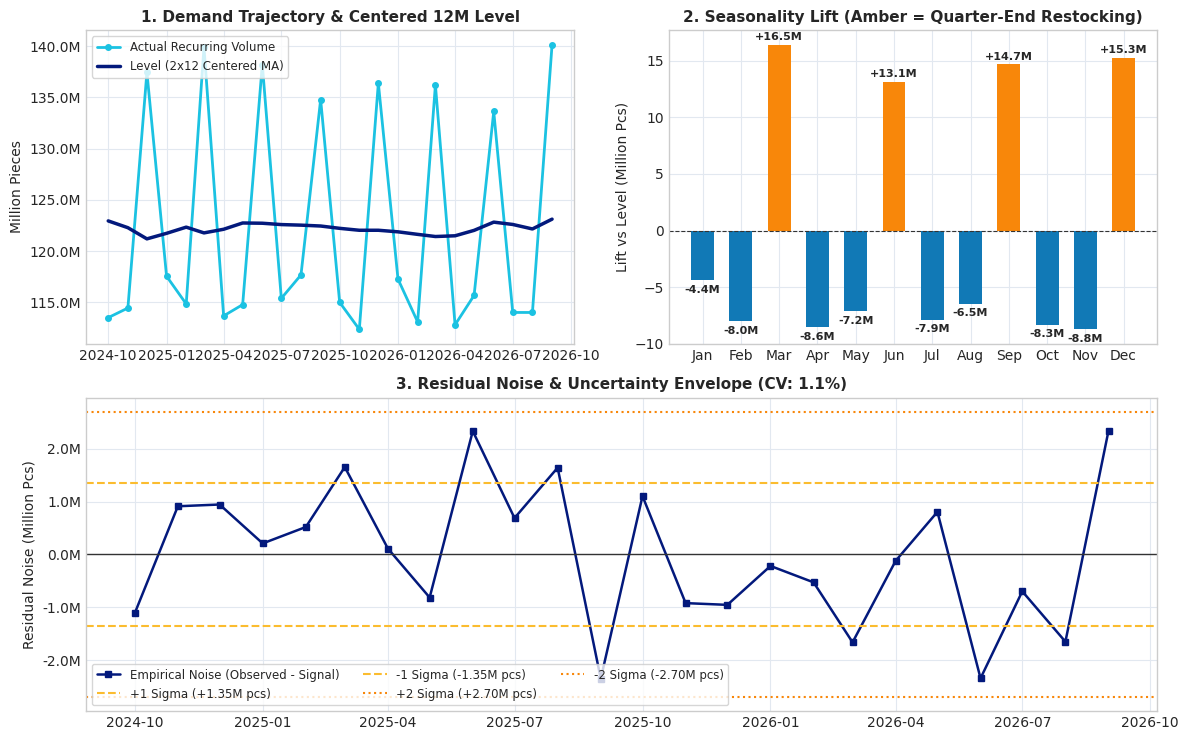

Decomposition Summary:
  - 12-Month Baseline Level : 122.22M pcs / month
  - Residual Noise Std (1s) : 1.35M pcs
  - Coefficient of Variation: 1.1% (High: Low residual variance; suitable for statistical baseline projection)


In [3]:
rec_only = fact_rec[fact_rec["demand_stream"] == "Recurring"].copy()
port_rec = rec_only.groupby("period_date")["stream_qty_pcs"].sum().reset_index()
port_rec["period_date"] = pd.to_datetime(port_rec["period_date"])
port_rec["Month"] = port_rec["period_date"].dt.month
port_rec = port_rec.sort_values("period_date").reset_index(drop=True)

dates = port_rec["period_date"]
series_port = pd.Series(port_rec["stream_qty_pcs"].values, index=dates)
decomp_df, decomp_metrics = src.run_3layer_decomposition(series_port, period=12)

fig = plt.figure(figsize=(12, 7.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1])

ax_p1 = fig.add_subplot(gs[0, 0])
ax_p1.plot(dates, decomp_df["observed"] / 1e6, color=AZURE["cyan"], lw=2.0, marker="o", ms=4, label="Actual Recurring Volume")
ax_p1.plot(dates, decomp_df["level"] / 1e6, color=AZURE["navy"], lw=2.5, label="Level (2x12 Centered MA)")
ax_p1.set_title("1. Demand Trajectory & Centered 12M Level", fontsize=11, fontweight="bold")
ax_p1.set_ylabel("Million Pieces")
ax_p1.legend(loc="upper left", fontsize=8.5, frameon=True, facecolor="white", edgecolor="#cccccc")
ax_p1.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.1fM"))

ax_p2 = fig.add_subplot(gs[0, 1])
m_lifts = pd.Series(decomp_metrics["monthly_lifts"])
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
qe_months = set(dim_cal.loc[dim_cal["is_quarter_end"] == 1, "month"].unique())
bar_colors = [AMBER["deep"] if m in qe_months else AZURE["medium"] for m in range(1, 13)]
ax_p2.bar(month_names, [m_lifts[m] / 1e6 for m in range(1, 13)], color=bar_colors, width=0.6)
ax_p2.axhline(0, color="#333333", lw=0.8, ls="--")
ax_p2.set_title("2. Seasonality Lift (Amber = Quarter-End Restocking)", fontsize=11, fontweight="bold")
ax_p2.set_ylabel("Lift vs Level (Million Pcs)")
for i, m in enumerate(range(1, 13)):
    v = m_lifts[m] / 1e6
    ax_p2.text(i, v + (0.4 if v >= 0 else -1.1), f"{v:+.1f}M", ha="center", fontsize=8, fontweight="bold")

ax_p3 = fig.add_subplot(gs[1, :])
sigma = decomp_metrics["sigma_noise"] / 1e6
ax_p3.plot(dates, decomp_df["noise"] / 1e6, color=AZURE["navy"], lw=1.8, marker="s", ms=5, label="Empirical Noise (Observed - Signal)")
ax_p3.axhline(0, color="#333333", lw=1.0)
ax_p3.axhline(+1 * sigma, color=AMBER["gold"], ls="--", lw=1.5, label=f"+1 Sigma (+{sigma:.2f}M pcs)")
ax_p3.axhline(-1 * sigma, color=AMBER["gold"], ls="--", lw=1.5, label=f"-1 Sigma (-{sigma:.2f}M pcs)")
ax_p3.axhline(+2 * sigma, color=AMBER["deep"], ls=":", lw=1.5, label=f"+2 Sigma (+{2*sigma:.2f}M pcs)")
ax_p3.axhline(-2 * sigma, color=AMBER["deep"], ls=":", lw=1.5, label=f"-2 Sigma (-{2*sigma:.2f}M pcs)")
ax_p3.set_title(f"3. Residual Noise & Uncertainty Envelope (CV: {decomp_metrics['cv_noise_pct']:.1f}%)", fontsize=11, fontweight="bold")
ax_p3.set_ylabel("Residual Noise (Million Pcs)")
ax_p3.legend(loc="lower left", ncol=3, fontsize=8.5, frameon=True, facecolor="white", edgecolor="#cccccc")
ax_p3.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.1fM"))

plt.tight_layout()
fig.savefig(os.path.join(fig_dir, "chapter1_3layer_decomposition_diagnostics.png"), dpi=150)
plt.show()

print("Decomposition Summary:")
print(f"  - 12-Month Baseline Level : {decomp_metrics['mean_level']/1e6:.2f}M pcs / month")
print(f"  - Residual Noise Std (1s) : {decomp_metrics['sigma_noise']/1e6:.2f}M pcs")
print(f"  - Coefficient of Variation: {decomp_metrics['cv_noise_pct']:.1f}% ({decomp_metrics['category']}: {decomp_metrics['recommendation']})")

## 2. Walk-Forward Backtest (12 Months)

We compare three candidate models and their equal average against a plain **Seasonal Naive** benchmark (`Actual(t-12)`) over the last 12 closed months (Oct 2025 – Sep 2026) in `src/models.py`:

- **Seasonal Naive**: repeats the same calendar month from 12 months ago.
- **Damped Naive (`phi = 0.70`)**: adds cumulative damped year-over-year drift (`sum_{i=1..h} phi^i * Drift_YoY`) to the seasonal lag.
- **Trend + Seasonality (OLS)**: removes zero-centered monthly seasonal factors first, fits a linear trend on the deseasonalized series, and adds the seasonal lift back.
- **Exponential Smoothing (Holt-Winters)**: additive level and 12-month seasonality with initial slope set to zero.
- **Combined Forecast**: simple average of Damped Naive, Trend + Seasonality, and Holt-Winters.

Over 12 test points, all models perform within 0.16 percentage points of the plain Seasonal Naive benchmark (1.85% portfolio WMAPE vs 1.69%–1.84%), which is well within sampling noise for `n = 12`. We use the simple average because combining the three specifications hedges against single-model drift across the 16 granular Brand x Channel series.

--- PORTFOLIO-LEVEL BACKTEST (12 MONTHS) ---
           Model Name  Portfolio WMAPE (%)  Forecast Bias (%)  MAE (Million Pcs)  RMSE (Million Pcs)
       Seasonal_Naive                 1.85               0.79               2.26                2.75
         Damped_Naive                 1.84               0.73               2.24                2.75
       Trend_Seasonal                 1.69               0.35               2.06                2.73
Exponential_Smoothing                 1.70               0.20               2.06                2.83
    Combined_Forecast                 1.73               0.43               2.11                2.75



--- GRANULAR 16-SERIES BACKTEST SUMMARY ---
           Model Name  Mean Series WMAPE (%)  Median Series WMAPE (%)
       Seasonal_Naive                   5.50                     5.27
         Damped_Naive                   5.49                     5.29
       Trend_Seasonal                   5.77                     5.66
Exponential_Smoothing                   5.78                     5.75
    Combined_Forecast                   5.65                     5.56
Individual model wins across 16 series: {'Damped_Naive': 12, 'Trend_Seasonal': 2, 'Exponential_Smoothing': 2}


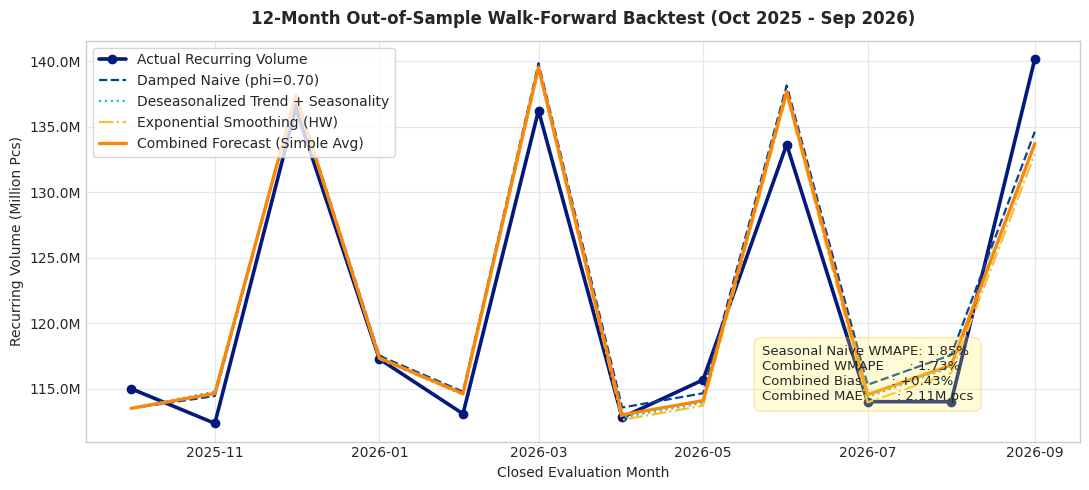

In [4]:
dates_str = port_rec["period_date"].dt.strftime("%Y-%m-%d").values
backtest_df, bt_metrics = src.run_walk_forward_backtest(
    port_rec["stream_qty_pcs"].values, port_rec["Month"].values, dates_str, min_train=12
)

bt_table = []
for m_name, m_vals in bt_metrics.items():
    bt_table.append({
        "Model Name": m_name,
        "Portfolio WMAPE (%)": round(m_vals["WMAPE"], 2),
        "Forecast Bias (%)": round(m_vals["Bias_pct"], 2),
        "MAE (Million Pcs)": round(m_vals["MAE"] / 1e6, 2),
        "RMSE (Million Pcs)": round(m_vals["RMSE"] / 1e6, 2),
    })

print("--- PORTFOLIO-LEVEL BACKTEST (12 MONTHS) ---")
print(pd.DataFrame(bt_table).to_string(index=False))

gran_bt_df = src.evaluate_granular_backtest(fact_rec, min_train=12)
model_cols = ["Seasonal_Naive", "Damped_Naive", "Trend_Seasonal", "Exponential_Smoothing", "Combined_Forecast"]
gran_summary = pd.DataFrame({
    "Model Name": model_cols,
    "Mean Series WMAPE (%)": [round(gran_bt_df[c].mean(), 2) for c in model_cols],
    "Median Series WMAPE (%)": [round(gran_bt_df[c].median(), 2) for c in model_cols],
})
best_3_wins = gran_bt_df[["Damped_Naive", "Trend_Seasonal", "Exponential_Smoothing"]].idxmin(axis=1).value_counts().to_dict()
print("\n--- GRANULAR 16-SERIES BACKTEST SUMMARY ---")
print(gran_summary.to_string(index=False))
print("Individual model wins across 16 series:", best_3_wins)

fig, ax = plt.subplots(figsize=(11, 5.0))
bt_dates = pd.to_datetime(backtest_df["period_date"])

ax.plot(bt_dates, backtest_df["actual"] / 1e6, label="Actual Recurring Volume", color=AZURE["navy"], lw=2.6, marker="o", ms=6)
ax.plot(bt_dates, backtest_df["pred_damped_naive"] / 1e6, label="Damped Naive (phi=0.70)", color=AZURE["royal"], lw=1.6, ls="--")
ax.plot(bt_dates, backtest_df["pred_trend_seasonal"] / 1e6, label="Deseasonalized Trend + Seasonality", color=AZURE["cyan"], lw=1.6, ls=":")
ax.plot(bt_dates, backtest_df["pred_exponential_smoothing"] / 1e6, label="Exponential Smoothing (HW)", color=AMBER["gold"], lw=1.6, ls="-.")
ax.plot(bt_dates, backtest_df["pred_combined"] / 1e6, label="Combined Forecast (Simple Avg)", color=AMBER["deep"], lw=2.4)

ax.set_title("12-Month Out-of-Sample Walk-Forward Backtest (Oct 2025 - Sep 2026)", fontsize=12, fontweight="bold", pad=12)
ax.set_ylabel("Recurring Volume (Million Pcs)", fontsize=10)
ax.set_xlabel("Closed Evaluation Month", fontsize=10)
ax.legend(frameon=True, facecolor="white", loc="upper left", edgecolor="#cccccc")
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.1fM"))

textstr = "\n".join((
    f"Seasonal Naive WMAPE: {bt_metrics['Seasonal_Naive']['WMAPE']:.2f}%",
    f"Combined WMAPE      : {bt_metrics['Combined_Forecast']['WMAPE']:.2f}%",
    f"Combined Bias       : {bt_metrics['Combined_Forecast']['Bias_pct']:+.2f}%",
    f"Combined MAE        : {bt_metrics['Combined_Forecast']['MAE']/1e6:.2f}M pcs",
))
props = dict(boxstyle="round,pad=0.6", facecolor=AMBER["lemon"], edgecolor=AMBER["orange"], alpha=0.25)
ax.text(0.68, 0.24, textstr, transform=ax.transAxes, fontsize=9.5, verticalalignment="top", bbox=props)

plt.tight_layout()
fig.savefig(os.path.join(fig_dir, "chapter2_walk_forward_backtest.png"), dpi=150)
plt.show()

## 3. 6-Month Volume Forecast & Multi-Step Bootstrap Range

To match the 6-month forecast horizon (Oct 2026 – Mar 2027), `src/models.py: collect_multistep_residuals` collects expanding-window out-of-sample forecast errors directly for each horizon step `h = 1..6`. `src/simulation.py` then resamples each horizon's empirical residual distribution across 5,000 runs without arbitrary variance-scaling assumptions.

- **Base forecast (730.3M pcs)**: expected 6-month recurring demand.
- **P10 floor (721.6M pcs)**: downside recurring volume for revenue risk budgeting.
- **P90 buffer (739.9M pcs)**: upper recurring demand bound (+9.6M pcs above base) used to size the recurring safety stock buffer.

Forward Period  Recurring P10 Floor (M pcs)  Recurring Base (M pcs)  Recurring P90 Buffer (M pcs)  Corporate Target (M pcs)  Non-Recurring Quota (M pcs)
       2026-10                       111.02                  113.81                        115.91                    158.92                        45.11
       2026-11                       110.11                  112.77                        115.18                    159.87                        47.10
       2026-12                       133.58                  136.31                        138.34                    186.71                        50.40
       2027-01                       113.46                  116.82                        123.58                    157.60                        40.78
       2027-02                       109.89                  113.29                        120.44                    159.84                        46.55
       2027-03                       133.84                  137.27               

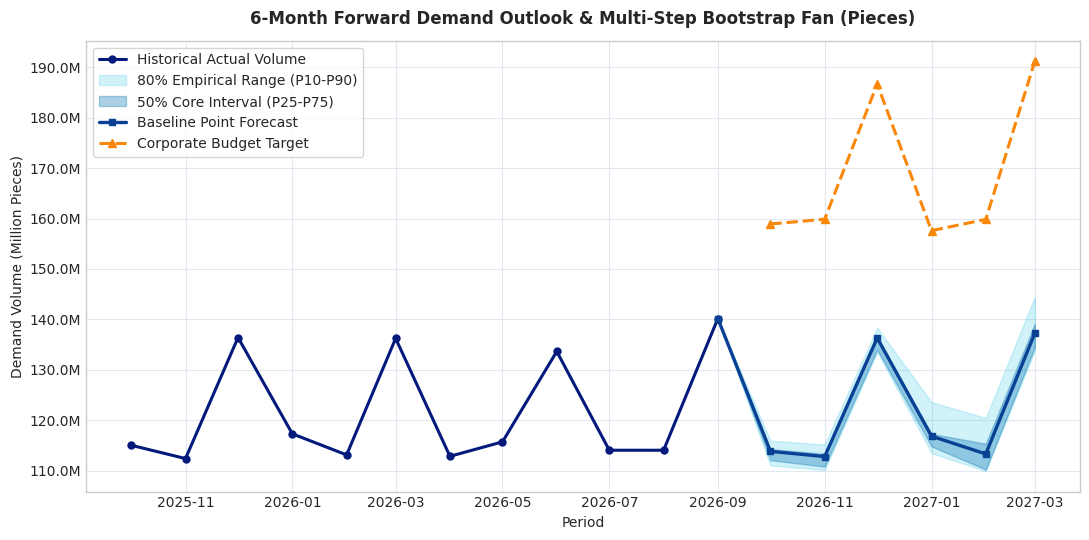

In [5]:
forward_df = src.project_recurring_forward_direct(
    port_rec["stream_qty_pcs"].values, port_rec["Month"].values, n_forward=6
)
multistep_resids = src.collect_multistep_residuals(
    port_rec["stream_qty_pcs"].values, port_rec["Month"].values, min_train=12, max_h=6
)

future_target_df = fact_target[fact_target["period_date"] >= fut_start].groupby("period_date")["target_qty_pcs"].sum().reset_index()
future_dates = pd.to_datetime(future_target_df["period_date"])
target_future_pcs = future_target_df["target_qty_pcs"].values

sim_paths, mc_summary, tot_summary = src.run_empirical_bootstrap_simulation(
    forward_df["point_forecast"].values,
    multistep_resids,
    n_simulations=5000,
    random_seed=42,
    target_values=target_future_pcs,
)
mc_summary["period_date"] = future_dates

display_mc = mc_summary[["period_date", "point_forecast", "p10_bear", "p50_base", "p90_bull", "target_value"]].copy()
display_mc["Forward Period"] = future_dates.dt.strftime("%Y-%m")
display_mc["Recurring P10 Floor (M pcs)"] = (display_mc["p10_bear"] / 1e6).round(2)
display_mc["Recurring Base (M pcs)"] = (display_mc["point_forecast"] / 1e6).round(2)
display_mc["Recurring P90 Buffer (M pcs)"] = (display_mc["p90_bull"] / 1e6).round(2)
display_mc["Corporate Target (M pcs)"] = (display_mc["target_value"] / 1e6).round(2)
display_mc["Non-Recurring Quota (M pcs)"] = (display_mc["Corporate Target (M pcs)"] - display_mc["Recurring Base (M pcs)"]).round(2)

tot_mc_row = pd.DataFrame([{
    "Forward Period": "6M Total",
    "Recurring P10 Floor (M pcs)": round(tot_summary["total_p10_bear"] / 1e6, 2),
    "Recurring Base (M pcs)": round(tot_summary["total_point_forecast"] / 1e6, 2),
    "Recurring P90 Buffer (M pcs)": round(tot_summary["total_p90_bull"] / 1e6, 2),
    "Corporate Target (M pcs)": round(tot_summary["total_target"] / 1e6, 2),
    "Non-Recurring Quota (M pcs)": round((tot_summary["total_target"] - tot_summary["total_point_forecast"]) / 1e6, 2),
}])

cols_to_print = [
    "Forward Period",
    "Recurring P10 Floor (M pcs)",
    "Recurring Base (M pcs)",
    "Recurring P90 Buffer (M pcs)",
    "Corporate Target (M pcs)",
    "Non-Recurring Quota (M pcs)",
]
print(pd.concat([display_mc[cols_to_print], tot_mc_row], ignore_index=True).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 5.5))
hist_slice = port_rec.iloc[-12:].copy()
ax.plot(hist_slice["period_date"], hist_slice["stream_qty_pcs"] / 1e6, color=AZURE["navy"], lw=2.2, marker="o", ms=5, label="Historical Actual Volume")

last_hist_date = hist_slice["period_date"].iloc[-1]
last_hist_val = hist_slice["stream_qty_pcs"].iloc[-1] / 1e6

fwd_dates_full = pd.concat([pd.Series([last_hist_date]), pd.Series(future_dates)], ignore_index=True)
base_full = [last_hist_val] + list(forward_df["point_forecast"].values / 1e6)
p25_full = [last_hist_val] + list(mc_summary["p25"].values / 1e6)
p75_full = [last_hist_val] + list(mc_summary["p75"].values / 1e6)
p10_full = [last_hist_val] + list(mc_summary["p10_bear"].values / 1e6)
p90_full = [last_hist_val] + list(mc_summary["p90_bull"].values / 1e6)

ax.fill_between(fwd_dates_full, p10_full, p90_full, color=AZURE["cyan"], alpha=0.20, label="80% Empirical Range (P10-P90)")
ax.fill_between(fwd_dates_full, p25_full, p75_full, color=AZURE["medium"], alpha=0.35, label="50% Core Interval (P25-P75)")
ax.plot(fwd_dates_full, base_full, color=AZURE["royal"], lw=2.4, marker="s", ms=5, label="Baseline Point Forecast")
ax.plot(future_dates, target_future_pcs / 1e6, color=AMBER["deep"], lw=2.2, ls="--", marker="^", ms=6, label="Corporate Budget Target")

ax.set_title("6-Month Forward Demand Outlook & Multi-Step Bootstrap Fan (Pieces)", fontsize=12, fontweight="bold", pad=12)
ax.set_ylabel("Demand Volume (Million Pieces)", fontsize=10)
ax.set_xlabel("Period", fontsize=10)
ax.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#cccccc")
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.1fM"))

plt.tight_layout()
fig.savefig(os.path.join(fig_dir, "chapter3_monte_carlo_fan_chart.png"), dpi=150)
plt.show()

## 4. Non-Recurring Quota vs. Historical Run-Rate (Pieces)

Subtracting the 730.3M pcs recurring forecast from the 1,014.2M pcs corporate target leaves a **283.9M pcs** total non-recurring quota. However, non-recurring orders are not zero in a normal period: over the last 6 months (Apr – Sep 2026), non-recurring shipments totaled **249.7M pcs** (~25.7% of volume).

Comparing the 283.9M pcs quota against the 249.7M pcs historical run-rate isolates the true **+34.2M pcs incremental stretch** that sales teams must generate above their normal commercial pace.

In [6]:
grid_df = src.build_bottom_up_grid_forecast(
    fact_rec,
    fact_target,
    dim_prod,
    dim_chan,
    forecast_func=src.project_recurring_forward_direct,
    bootstrap_func=src.run_empirical_bootstrap_simulation,
    future_start_date=fut_start,
    n_forward=6,
)

ch_exposure = src.build_channel_revenue_exposure_table(grid_df)
display_ch_pcs = ch_exposure[[
    "channel_code", "channel_name", "target_pcs", "rec_p50_pcs",
    "gap_pcs", "hist_nr_pcs", "stretch_pcs"
]].copy()
display_ch_pcs.columns = [
    "Channel Code",
    "Channel Name",
    "Target Budget (M pcs)",
    "Recurring Base (M pcs)",
    "Total Non-Rec Quota (M pcs)",
    "Last 6M Non-Rec Run-Rate (M pcs)",
    "Incremental Stretch (M pcs)",
]
for c in display_ch_pcs.columns[2:]:
    display_ch_pcs[c] = (display_ch_pcs[c] / 1e6).round(2)

print("--- 6-MONTH VOLUME QUOTA VS. HISTORICAL RUN-RATE BY CHANNEL (MILLION PIECES) ---")
print(display_ch_pcs.to_string(index=False))

b_exposure = src.build_brand_revenue_exposure_table(grid_df)
display_b_pcs = b_exposure[[
    "brand_code", "brand_name", "modality", "target_pcs", "rec_p50_pcs",
    "gap_pcs", "hist_nr_pcs", "stretch_pcs"
]].copy()
display_b_pcs.columns = [
    "Brand Code",
    "Brand Name",
    "Modality",
    "Target Budget (M pcs)",
    "Recurring Base (M pcs)",
    "Total Non-Rec Quota (M pcs)",
    "Last 6M Non-Rec Run-Rate (M pcs)",
    "Incremental Stretch (M pcs)",
]
for c in display_b_pcs.columns[3:]:
    display_b_pcs[c] = (display_b_pcs[c] / 1e6).round(2)

print("\n--- 6-MONTH VOLUME QUOTA VS. HISTORICAL RUN-RATE BY BRAND (MILLION PIECES) ---")
print(display_b_pcs.to_string(index=False))

--- 6-MONTH VOLUME QUOTA VS. HISTORICAL RUN-RATE BY CHANNEL (MILLION PIECES) ---
   Channel Code                    Channel Name  Target Budget (M pcs)  Recurring Base (M pcs)  Total Non-Rec Quota (M pcs)  Last 6M Non-Rec Run-Rate (M pcs)  Incremental Stretch (M pcs)
 CH_CLINIC_INST       Clinics & Ophthalmologist                 154.60                  110.58                        44.02                             38.22                         5.80
  CH_DIRECT_ACC     Direct Independent Accounts                 101.20                   72.98                        28.22                             25.31                         2.91
      CH_ONLINE E-Commerce / Direct-to-Consumer                 349.32                  253.79                        95.53                             88.93                         6.60
CH_RETAIL_CHAIN           Optical Retail Chains                 409.06                  292.93                       116.14                             97.21              

## 5. Gross-to-Net Financials: Why Forecast Volume First

In the accounting ledger (`fact_sales_transaction.csv` and `fact_trade_contra.csv`), quarterly volume rebates (`VOLUME_REBATE`) are settled in lump sums at the end of March, June, September, and December. Contra deductions jump from ~7.6% in normal months to ~35.8% on quarter-end months, making booked Net Sales drop right when physical shipments peak.

Forecasting ledger Net Sales directly would bake those accounting dips into the demand forecast. Instead, we forecast physical pieces first and apply each channel's annual contra rate (`src/finance.py`):

```text
Net Revenue (JPY) = Volume (Pcs) * Base List Price (JPY) * (1 - Channel Contra Rate)
```

--- TRADE CONTRA BREAKDOWN (% OF GROSS SALES) FROM fact_trade_contra.csv ---
contra_category                     PROMO_DISPLAY  RETUR_ALLOWANCE  VOLUME_REBATE  Total Contra (%)
Regular Months (16M)                         4.97             1.53           1.15              7.64
Quarter-End Settlement Months (8M)           7.86             2.14          25.73             35.74


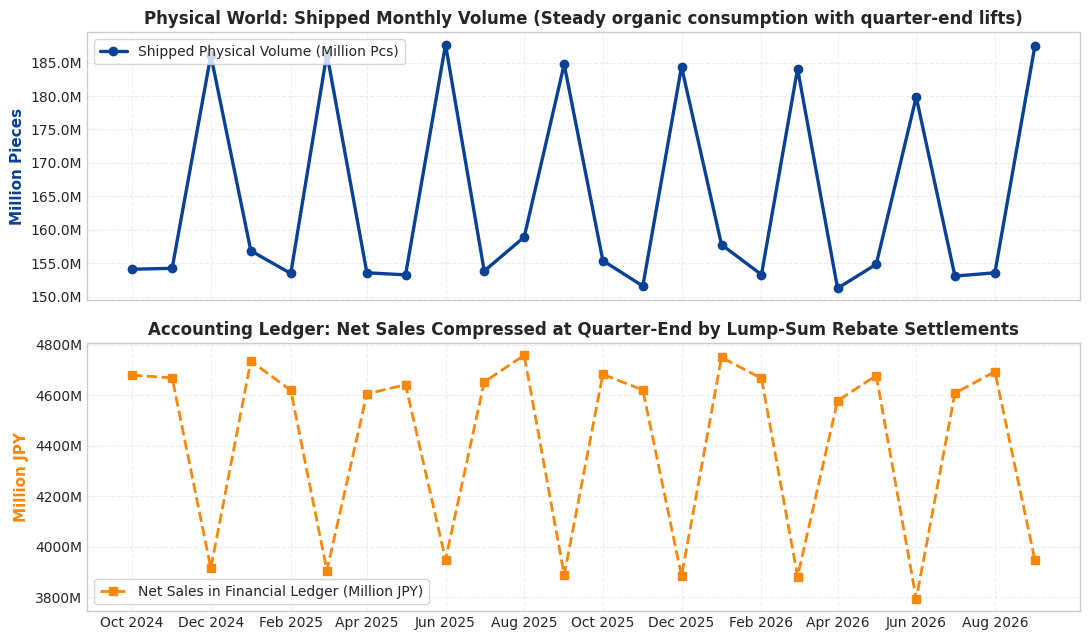

In [7]:
contra_with_cal = fact_contra.merge(dim_cal[["period_date", "is_quarter_end"]], on="period_date")
sales_with_cal = fact_sales.merge(dim_cal[["period_date", "is_quarter_end"]], on="period_date")
gross_by_qe = sales_with_cal.groupby("is_quarter_end")["gross_sales_amt"].sum()

contra_breakdown = (
    contra_with_cal.groupby(["is_quarter_end", "contra_category"])["contra_spend_amt"]
    .sum()
    .unstack()
)
contra_pct_table = contra_breakdown.div(gross_by_qe, axis=0) * 100.0
contra_pct_table["Total Contra (%)"] = contra_pct_table.sum(axis=1)
contra_pct_table.index = ["Regular Months (16M)", "Quarter-End Settlement Months (8M)"]
print("--- TRADE CONTRA BREAKDOWN (% OF GROSS SALES) FROM fact_trade_contra.csv ---")
print(contra_pct_table.round(2).to_string())

m_sales = fact_sales.groupby("period_date").agg({
    "qty_pcs": "sum",
    "gross_sales_amt": "sum",
    "contra_amt": "sum",
    "net_sales_amt": "sum",
}).reset_index()
m_sales["period_date"] = pd.to_datetime(m_sales["period_date"])
m_sales = m_sales.sort_values("period_date").reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
sales_dates = m_sales["period_date"]

ax1.plot(sales_dates, m_sales["qty_pcs"] / 1e6, color=AZURE["royal"], lw=2.4, marker="o", label="Shipped Physical Volume (Million Pcs)")
ax1.set_ylabel("Million Pieces", fontsize=11, fontweight="bold", color=AZURE["royal"])
ax1.set_title("Physical World: Shipped Monthly Volume (Steady organic consumption with quarter-end lifts)", fontsize=12, fontweight="bold")
ax1.grid(True, linestyle="--", color="#E2E8F0", alpha=0.7)
ax1.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#cccccc")
ax1.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.1fM"))

ax2.plot(sales_dates, m_sales["net_sales_amt"] / 1e6, color=AMBER["deep"], lw=2.0, marker="s", ls="--", label="Net Sales in Financial Ledger (Million JPY)")
ax2.set_ylabel("Million JPY", fontsize=11, fontweight="bold", color=AMBER["deep"])
ax2.set_title("Accounting Ledger: Net Sales Compressed at Quarter-End by Lump-Sum Rebate Settlements", fontsize=12, fontweight="bold")
ax2.grid(True, linestyle="--", color="#E2E8F0", alpha=0.7)
ax2.legend(loc="lower left", frameon=True, facecolor="white", edgecolor="#cccccc")
ax2.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.0fM"))

plt.xticks(sales_dates[::2], [d.strftime("%b %Y") for d in sales_dates[::2]], rotation=0)
plt.tight_layout()
fig.savefig(os.path.join(fig_dir, "chapter1_accounting_trap_physical_vs_net.png"), dpi=150)
plt.show()

## 6. Net Revenue Gap & Incremental Stretch (Million JPY)

Converting the bottom-up volume forecast into JPY gives a **¥19,360.4M** recurring baseline (diversified portfolio P10 floor: **¥19,144.3M**) against the **¥27,233.7M** budget. Of the **¥7,873.3M** total non-recurring revenue quota, **¥6,899.5M** is covered by the historical 6-month non-recurring run-rate and **+¥973.8M** is net incremental stretch.

--- BRAND-LEVEL NET REVENUE QUOTA & STRETCH (OCT 2026 - MAR 2027) ---
Brand Code      Brand Name  Target Net Rev (M JPY)  Rec Base (M JPY)  Downside P10 (M JPY)  Total Non-Rec Quota (M JPY)  Hist 6M Non-Rec (M JPY)  Incremental Stretch (M JPY)
   BRAND_A         Brand A                 12184.1            9827.0                9623.2                       2357.1                   2112.0                        245.1
   BRAND_B         Brand B                  9257.1            5014.8                4896.9                       4242.4                   3617.8                        624.5
   BRAND_C         Brand C                  3576.9            2567.7                2497.1                       1009.2                    912.5                         96.7
   BRAND_D         Brand D                  2215.6            1950.9                1911.8                        264.7                    257.3                          7.5
     TOTAL Portfolio Total                 27233.7          

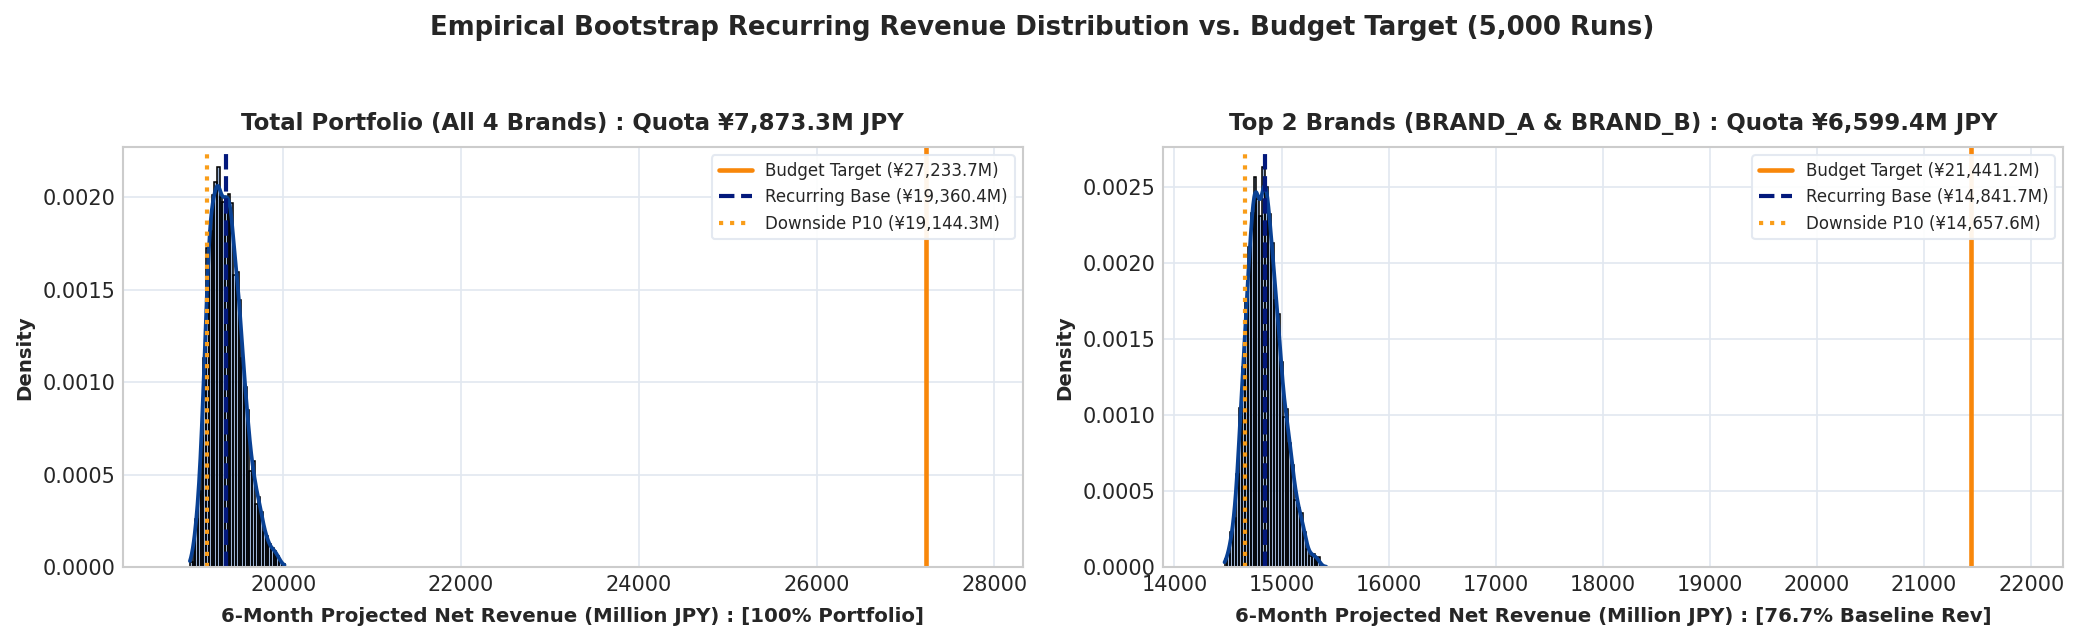

In [8]:
display_b_jpy = b_exposure[[
    "brand_code", "brand_name", "target_jpy", "rec_p50_jpy", "rec_p10_jpy",
    "gap_jpy", "hist_nr_jpy", "stretch_jpy"
]].copy()
display_b_jpy.columns = [
    "Brand Code", "Brand Name", "Target Net Rev (M JPY)", "Rec Base (M JPY)", "Downside P10 (M JPY)",
    "Total Non-Rec Quota (M JPY)", "Hist 6M Non-Rec (M JPY)", "Incremental Stretch (M JPY)"
]
for col in display_b_jpy.columns[2:]:
    display_b_jpy[col] = (display_b_jpy[col] / 1e6).round(1)

print("--- BRAND-LEVEL NET REVENUE QUOTA & STRETCH (OCT 2026 - MAR 2027) ---")
print(display_b_jpy.to_string(index=False))

display_ch_jpy = ch_exposure[[
    "channel_code", "channel_name", "contra_rate", "target_jpy", "rec_p50_jpy",
    "rec_p10_jpy", "gap_jpy", "hist_nr_jpy", "stretch_jpy"
]].copy()
display_ch_jpy.columns = [
    "Channel Code", "Channel Name", "Contra Rate", "Target Net Rev (M JPY)", "Rec Base (M JPY)",
    "Downside P10 (M JPY)", "Total Non-Rec Quota (M JPY)", "Hist 6M Non-Rec (M JPY)", "Incremental Stretch (M JPY)"
]
display_ch_jpy["Contra Rate"] = (display_ch_jpy["Contra Rate"] * 100.0).round(1).astype(str) + "%"
for col in display_ch_jpy.columns[3:]:
    display_ch_jpy[col] = (display_ch_jpy[col] / 1e6).round(1)

print("\n--- CHANNEL-LEVEL NET REVENUE QUOTA & STRETCH (OCT 2026 - MAR 2027) ---")
print(display_ch_jpy.to_string(index=False))

port_sim_jpy = np.sum(np.vstack(grid_df["sim_tot_jpy"].values), axis=0) / 1e6
top2_brands = b_exposure.iloc[:-1].nlargest(2, "target_jpy")["brand_code"].tolist()
core_mask = grid_df["brand_code"].isin(top2_brands)
core_sim_jpy = np.sum(np.vstack(grid_df.loc[core_mask, "sim_tot_jpy"].values), axis=0) / 1e6

tot_target_jpy = grid_df["target_jpy"].sum() / 1e6
tot_base_jpy = grid_df["rec_p50_jpy"].sum() / 1e6
tot_p10_jpy = float(np.percentile(port_sim_jpy, 10))

core_target_jpy = grid_df.loc[core_mask, "target_jpy"].sum() / 1e6
core_base_jpy = grid_df.loc[core_mask, "rec_p50_jpy"].sum() / 1e6
core_p10_jpy = float(np.percentile(core_sim_jpy, 10))
core_rev_share = (core_base_jpy / tot_base_jpy) * 100.0

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), dpi=150)

exec_specs = [
    {
        "ax": axes[0],
        "vals": port_sim_jpy,
        "title": f"Total Portfolio (All 4 Brands) : Quota ¥{tot_target_jpy - tot_base_jpy:,.1f}M JPY",
        "xlabel": "6-Month Projected Net Revenue (Million JPY) : [100% Portfolio]",
        "target": tot_target_jpy,
        "base": tot_base_jpy,
        "p10": tot_p10_jpy,
        "xlim": (min(port_sim_jpy) * 0.96, tot_target_jpy * 1.04),
    },
    {
        "ax": axes[1],
        "vals": core_sim_jpy,
        "title": f"Top 2 Brands ({' & '.join(top2_brands)}) : Quota ¥{core_target_jpy - core_base_jpy:,.1f}M JPY",
        "xlabel": f"6-Month Projected Net Revenue (Million JPY) : [{core_rev_share:.1f}% Baseline Rev]",
        "target": core_target_jpy,
        "base": core_base_jpy,
        "p10": core_p10_jpy,
        "xlim": (min(core_sim_jpy) * 0.96, core_target_jpy * 1.04),
    },
]

for s in exec_specs:
    ax = s["ax"]
    sns.histplot(
        s["vals"],
        kde=True,
        ax=ax,
        color=AZURE["royal"],
        bins=35,
        stat="density",
        alpha=0.40,
        edgecolor="black",
        linewidth=0.75,
        line_kws={"linewidth": 1.8, "color": AZURE["navy"]},
    )

    ax.axvline(s["target"], color=AMBER["deep"], linestyle="-", linewidth=2.2, label=f"Budget Target (¥{s['target']:,.1f}M)")
    ax.axvline(s["base"], color=AZURE["navy"], linestyle="--", linewidth=2.0, label=f"Recurring Base (¥{s['base']:,.1f}M)")
    ax.axvline(s["p10"], color=AMBER["orange"], linestyle=":", linewidth=2.0, label=f"Downside P10 (¥{s['p10']:,.1f}M)")

    ax.set_title(s["title"], fontweight="bold", fontsize=11, pad=8)
    ax.set_xlabel(s["xlabel"], fontsize=9.5, fontweight="bold", labelpad=6)
    ax.set_ylabel("Density", fontsize=9.5, fontweight="bold")
    ax.set_xlim(s["xlim"])
    ax.legend(fontsize=8, loc="upper right", frameon=True, facecolor="white", edgecolor="#e2e8f0", framealpha=0.92)

plt.suptitle("Empirical Bootstrap Recurring Revenue Distribution vs. Budget Target (5,000 Runs)", fontsize=12.5, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0.02, 1, 0.94])
fig.savefig(os.path.join(fig_dir, "chapter3_monte_carlo_revenue_density.png"), dpi=150)
plt.show()

## 7. Price Elasticity (`PED`) & Consistent Pricing / Rebate Scenarios

`src/finance.py: estimate_channel_ped` estimates channel price elasticity from the 16 non-settlement months (`dim_calendar.is_quarter_end == 0`) by deseasonalizing volume (`Q_adj`) and fitting a log-log OLS regression on realized net price (`P_net = Net Sales / Q`):

```text
ln(Q_adj) = alpha + PED * ln(P_net)
```

*Methodological note:* Because this is a synthetic dataset, the OLS regression recovers the ground-truth elasticity parameters stored in `dim_channel.csv` across `n = 16` non-settlement observations. In real observational ledger data, volume-tiered rebates create reverse causality (higher volume lowers effective net price), so estimating true demand elasticity requires instrumental variables or controlled pricing experiments.

Critically, both a **+5% list price hike** and an **unconditional -2pp contra rebate cut** raise the effective net price `P_net`. Applying the constant-elasticity response `Q_new = Q_base * (P_net_new / P_net_base) ^ PED` consistently to both levers shows:
- **Clinics (`PED = 0.00, SE = 0.69`)**: demand is prescription-driven and price-inelastic; both a +5% list price hike (+¥36.0M/mo) and an unconditional -2pp rebate cut (+¥16.1M/mo) expand net revenue with zero volume loss.
- **Retail Chains (`PED = -1.11, SE = 0.18`) & Direct Accounts (`PED = -1.43, SE = 0.26`)**: raising effective net price via either a +5% list price hike (-¥9.4M/mo and -¥9.5M/mo) or an unconditional -2pp rebate cut (-¥4.7M/mo and -¥4.6M/mo) loses volume and net revenue. Rebate optimization in these channels must keep baseline net prices intact and pay tier incentives strictly on incremental volume above the recurring baseline.
- **Online (`PED = -4.51, SE = 0.56`)**: highly price-elastic; a +5% list price hike (-19.8% volume, -¥231.2M/mo) or an unconditional -2pp promo cut (-10.8% volume, -¥124.9M/mo) causes severe attrition.

--- LOG-LOG OLS PRICE ELASTICITY ESTIMATES (16 NON-SETTLEMENT MONTHS) ---
   channel_code  estimated_ped  std_error  r_squared  n_obs
 CH_CLINIC_INST          -0.00       0.69       0.00     16
  CH_DIRECT_ACC          -1.43       0.26       0.68     16
      CH_ONLINE          -4.51       0.56       0.82     16
CH_RETAIL_CHAIN          -1.11       0.18       0.74     16

--- CHANNEL PRICING & REBATE SCENARIOS (CONSTANT-ELASTICITY DEMAND) ---
   channel_code                    channel_name                      scenario  net_price_chg_pct  vol_chg_pct  Monthly Vol (M pcs)  Net Rev (M JPY)  Net Delta (M JPY)
 CH_CLINIC_INST       Clinics & Ophthalmologist                      Baseline               0.00          0.0                24.56            719.9                0.0
 CH_CLINIC_INST       Clinics & Ophthalmologist           +5% List Price Hike               5.00          0.0                24.56            755.9               36.0
 CH_CLINIC_INST       Clinics & Ophthalmologist Unco

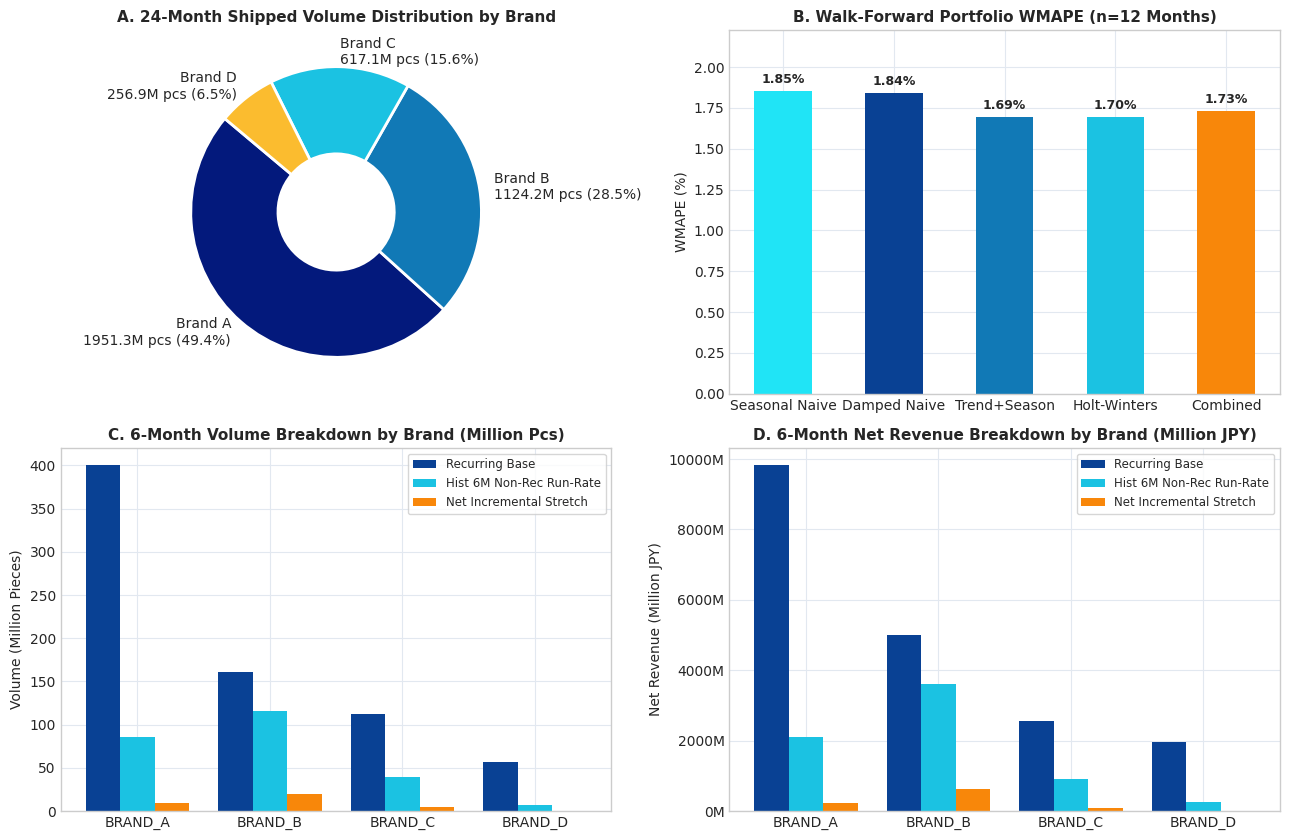

In [9]:
ped_est_df = src.estimate_channel_ped(fact_sales, dim_cal)
print("--- LOG-LOG OLS PRICE ELASTICITY ESTIMATES (16 NON-SETTLEMENT MONTHS) ---")
print(ped_est_df.to_string(index=False))

n_hist_months = int((dim_cal["is_future_target_horizon"] == 0).sum())
sales_chan = fact_sales.groupby("channel_code").agg({
    "qty_pcs": "sum",
    "gross_sales_amt": "sum",
    "contra_amt": "sum",
}).reset_index()
sales_chan["avg_monthly_qty"] = sales_chan["qty_pcs"] / float(n_hist_months)
sales_chan["avg_gross_price"] = sales_chan["gross_sales_amt"] / sales_chan["qty_pcs"]

merged_chan = sales_chan.merge(dim_chan, on="channel_code").merge(ped_est_df, on="channel_code")

scenario_rows = []
for _, row in merged_chan.iterrows():
    c_scenarios = src.evaluate_commercial_action_scenarios(
        row["channel_code"],
        row["channel_name"],
        row["avg_monthly_qty"],
        row["avg_gross_price"],
        row["target_contra_rate"],
        row["estimated_ped"],
    )
    scenario_rows.append(c_scenarios)

all_scenarios_df = pd.concat(scenario_rows, ignore_index=True)
action_table = all_scenarios_df[
    all_scenarios_df["scenario"].isin(["Baseline", "+5% List Price Hike", "Unconditional -2pp Contra Cut"])
].copy()
action_table["Monthly Vol (M pcs)"] = (action_table["monthly_vol_pcs"] / 1e6).round(2)
action_table["Net Rev (M JPY)"] = (action_table["net_revenue_jpy"] / 1e6).round(1)
action_table["Net Delta (M JPY)"] = (action_table["net_rev_delta_jpy"] / 1e6).round(1)

print("\n--- CHANNEL PRICING & REBATE SCENARIOS (CONSTANT-ELASTICITY DEMAND) ---")
print(action_table[[
    "channel_code", "channel_name", "scenario", "net_price_chg_pct",
    "vol_chg_pct", "Monthly Vol (M pcs)", "Net Rev (M JPY)", "Net Delta (M JPY)"
]].to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

brand_totals = fact_rec.groupby("brand_code")["stream_qty_pcs"].sum()
prod_names = dim_prod.set_index("brand_code")["brand_name"].to_dict()
brand_labels = [f"{prod_names[b]}\n{v/1e6:.1f}M pcs ({v/brand_totals.sum()*100:.1f}%)" for b, v in brand_totals.items()]
pie_colors = [AZURE["navy"], AZURE["medium"], AZURE["cyan"], AMBER["gold"]]
axes[0, 0].pie(
    brand_totals,
    labels=brand_labels,
    colors=pie_colors,
    startangle=140,
    wedgeprops=dict(width=0.6, edgecolor="white", lw=2),
)
axes[0, 0].set_title("A. 24-Month Shipped Volume Distribution by Brand", fontsize=11, fontweight="bold")

models_eval = ["Seasonal Naive", "Damped Naive", "Trend+Season", "Holt-Winters", "Combined"]
wmape_list = [
    bt_metrics["Seasonal_Naive"]["WMAPE"],
    bt_metrics["Damped_Naive"]["WMAPE"],
    bt_metrics["Trend_Seasonal"]["WMAPE"],
    bt_metrics["Exponential_Smoothing"]["WMAPE"],
    bt_metrics["Combined_Forecast"]["WMAPE"],
]
leader_colors = [AZURE["aqua"], AZURE["royal"], AZURE["medium"], AZURE["cyan"], AMBER["deep"]]
axes[0, 1].bar(models_eval, wmape_list, color=leader_colors, width=0.52)
axes[0, 1].set_ylabel("WMAPE (%)", fontsize=10)
axes[0, 1].set_ylim(0, max(wmape_list) * 1.2)
axes[0, 1].set_title("B. Walk-Forward Portfolio WMAPE (n=12 Months)", fontsize=11, fontweight="bold")
for i, v in enumerate(wmape_list):
    axes[0, 1].text(i, v + 0.05, f"{v:.2f}%", ha="center", fontsize=9, fontweight="bold")

b_rows = b_exposure[b_exposure["brand_code"] != "TOTAL"].copy()
b_codes = b_rows["brand_code"].tolist()
b_rec_pcs = (b_rows["rec_p50_pcs"] / 1e6).values
b_hist_nr_pcs = (b_rows["hist_nr_pcs"] / 1e6).values
b_stretch_pcs = (b_rows["stretch_pcs"] / 1e6).values
x = np.arange(len(b_codes))
w = 0.26

axes[1, 0].bar(x - w, b_rec_pcs, width=w, color=AZURE["royal"], label="Recurring Base")
axes[1, 0].bar(x, b_hist_nr_pcs, width=w, color=AZURE["cyan"], label="Hist 6M Non-Rec Run-Rate")
axes[1, 0].bar(x + w, b_stretch_pcs, width=w, color=AMBER["deep"], label="Net Incremental Stretch")
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(b_codes)
axes[1, 0].set_ylabel("Volume (Million Pieces)", fontsize=10)
axes[1, 0].set_title("C. 6-Month Volume Breakdown by Brand (Million Pcs)", fontsize=11, fontweight="bold")
axes[1, 0].legend(frameon=True, facecolor="white", loc="upper right", edgecolor="#cccccc", fontsize=8.5)

b_rec_jpy = (b_rows["rec_p50_jpy"] / 1e6).values
b_hist_nr_jpy = (b_rows["hist_nr_jpy"] / 1e6).values
b_stretch_jpy = (b_rows["stretch_jpy"] / 1e6).values

axes[1, 1].bar(x - w, b_rec_jpy, width=w, color=AZURE["royal"], label="Recurring Base")
axes[1, 1].bar(x, b_hist_nr_jpy, width=w, color=AZURE["cyan"], label="Hist 6M Non-Rec Run-Rate")
axes[1, 1].bar(x + w, b_stretch_jpy, width=w, color=AMBER["deep"], label="Net Incremental Stretch")
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(b_codes)
axes[1, 1].set_ylabel("Net Revenue (Million JPY)", fontsize=10)
axes[1, 1].set_title("D. 6-Month Net Revenue Breakdown by Brand (Million JPY)", fontsize=11, fontweight="bold")
axes[1, 1].legend(frameon=True, facecolor="white", loc="upper right", edgecolor="#cccccc", fontsize=8.5)
axes[1, 1].yaxis.set_major_formatter(ticker.FormatStrFormatter("%.0fM"))

plt.tight_layout()
fig.savefig(os.path.join(fig_dir, "chapter4_executive_revenue_bridge.png"), dpi=150)
plt.show()

## 8. Summary of Findings & Planning Implications

*Note: Numbers below reflect the synthetic dataset and illustrate how the two-stage forecasting workflow informs commercial and supply planning.*

- **Baseline vs. Incremental Commercial Stretch**:
  - Recurring refills cover 730.3M pcs (¥19,360.4M) of the 1,014.2M pcs (¥27,233.7M) 6-month target.
  - Of the remaining 283.9M pcs (¥7,873.3M) non-recurring quota, 249.7M pcs (¥6,899.5M) matches the last-6-month non-recurring run-rate, leaving **+34.2M pcs (+¥973.8M)** of true incremental stretch.
  - Brand B accounts for **+20.1M pcs (+¥624.5M)**, or **64.1%** of the company's net incremental revenue stretch, and Optical Retail Chains account for **+18.9M pcs (+¥502.0M)** by channel.
- **Supply Chain Capacity Sizing**:
  - Factory capacity and raw material buffers must cover the full 1,014.2M pcs budget target plus the +9.6M pcs recurring P90 buffer (**1,023.8M pcs** total), rather than sizing capacity on recurring volume alone.
- **Channel Pricing & Rebate Rules (Derived from PED Scenarios)**:
  - **Clinics (`PED = 0.00`)**: only channel where an unconditional -2pp contra rebate cut (+¥16.1M/mo) or a +5% list price increase (+¥36.0M/mo) raises net revenue without volume loss.
  - **Retail Chains (`PED = -1.11`) & Direct Accounts (`PED = -1.43`)**: unconditional rebate cuts raise effective net price and reduce net revenue (-¥4.7M/mo and -¥4.6M/mo). Keep baseline effective prices steady and tie rebate tiers strictly to incremental volume above the historical run-rate.
  - **Online (`PED = -4.51`)**: highly sensitive to unit net price (-¥124.9M/mo on a -2pp promo cut; -¥231.2M/mo on a +5% price hike). Maintain competitive unit pricing to protect the 253.8M pcs recurring base.